# Assessment of Antarctic polynya representation - extent and seasonality
- Sea ice spatial extent and temporal variability
- Comparison between OM3, OM2 and where available observations.

### NOTES TO DO:
- Want to add OM2 data for comparison too.
- Copy averaged Tamura data to a directory for public access.


In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# e.g. https://access-om3-configs.access-hive.org.au/latest/Experiments/
# esm_file = "/g/data/ol01/outputs/access-om3-8km/MC_8km_jra_ryf-test2-expt-c349f800/experiment_datastore.json"
# esm_file = "/g/data/ik11/outputs/access-om3-025/MC_25km_era_iaf+wombatlite-test5.1-era-b3d64e3d/datastore.json"
# esm_file = "/g/data/ik11/outputs/access-om3-025/MC_25km_jra_ryf+wombatlite-test5.1-5c6ad028/datastore.json"
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)

In [3]:
import xarray as xr
import cf_xarray
import intake
import cartopy.crs as ccrs
import cmocean as cm
import numpy as np
import matplotlib.pyplot as plt
from distributed import Client
import intake
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


In [4]:
client = Client(threads_per_worker=1)
print(client.dashboard_link)

/proxy/8787/status


2026-11-18 11:22:10,283 - distributed.scheduler - ERROR - Task 'finalize-hlgfinalizecompute-8b8d3352ec524a9fa6a4566c6760954b' has 14.70 GiB worth of input dependencies, but worker tcp://127.0.0.1:45713 has memory_limit set to 8.97 GiB. It seems like you called client.compute() on a huge collection. Consider writing to distributed storage or slicing/reducing first.


In [5]:
IAF = esm_file.find('iaf') > 0
IAF

True

In [6]:


import matplotlib.path as mpath
theta = np.linspace(0, 2*np.pi, 100)
map_circle = mpath.Path(np.vstack([np.sin(theta), np.cos(theta)]).T * 0.5 + [0.5, 0.5])

### Open the intake-esm datastore

In [7]:
COLUMNS_WITH_ITERABLES = [
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
]

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=COLUMNS_WITH_ITERABLES
)

In [8]:
#datastore.df   <----- MAGIC COMMAND!!

In [9]:
def available_variables(datastore):
    """Return a pandas dataframe summarising the variables in a datastore"""
    variable_columns = [col for col in datastore.df.columns if "variable" in col]
    return (
        datastore.df[variable_columns]
        .explode(variable_columns)
        .drop_duplicates()
        .set_index("variable")
        .sort_index()
    )
import pandas as pd
# Set option to display all rows
pd.set_option('display.max_rows', None)

# Set option to display all columns (optional, but often useful)
pd.set_option('display.max_columns', None) 

### Print out the available ocean and sea ice variables

In [10]:
available_variables(datastore.search(realm="ocean"))

,variable_long_name,variable_standard_name,variable_cell_methods,variable_units
variable,,,,
APE,Total Interface APE,,,Joules
Ah,Area of h cells,,,m2
Ahh,Biharmonic Horizontal Viscosity at h Points,,area:mean z_l:mean yh:mean xh:mean time: mean,m4 s-1
Aq,Area of q cells,,,m2
Chl_opac,Surface chlorophyll A concentration used to fi...,,area:mean yh:mean xh:mean time: mean,mg m-3
Coriolis,Coriolis parameter at corner (Bu) points,,time: point,s-1
D,Basin Depth,,,meter
En,Total Energy,,,Joules
GM_sfn_y,Parameterized Meridional Overturning Streamfun...,,rho2_i:point yq:point xh:mean time: mean,m3 s-1


In [11]:
available_variables(datastore.search(realm="seaIce"))

,variable_long_name,variable_standard_name,variable_cell_methods,variable_units
variable,,,,
ANGLE,angle grid makes with latitude line on U grid,,,radians
ANGLET,angle grid makes with latitude line on T grid,,,radians
ELAT,E grid center latitude,,,degrees_north
ELON,E grid center longitude,,,degrees_east
HTE,T cell width on East side,,,m
HTN,T cell width on North side,,,m
NCAT,category maximum thickness,,,m
NFSD,category floe size (center),,,m
NLAT,N grid center latitude,,,degrees_north


# Multi-year comparison

In [12]:
date_start = '1992-01-01' 
date_end = '2016-12-31'

### Load ACCESS data

In [13]:
grid = datastore.search(variable=['TLAT','TLON']).to_dask()

In [14]:
grid = grid.fillna(0)

In [17]:
SIP_congel = datastore.search(variable="congel").to_dask(
    xarray_combine_by_coords_kwargs = dict( # These kwargs can make things faster
        compat="override",
        data_vars="minimal",
        coords="minimal",
    ),
    xarray_open_kwargs = dict(
        chunks={"yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
        # chunks={"time": -1}, # Good for temporal operations, but not spatial
        decode_timedelta=True
    )
)

SIP_frazil = datastore.search(variable="frazil").to_dask(
    xarray_combine_by_coords_kwargs = dict( # These kwargs can make things faster
        compat="override",
        data_vars="minimal",
        coords="minimal",
    ),
    xarray_open_kwargs = dict(
        chunks={"yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
        # chunks={"time": -1}, # Good for temporal operations, but not spatial
        decode_timedelta=True
    )
)

SIP_meltt = datastore.search(variable="meltt_m").to_dask(
    xarray_combine_by_coords_kwargs = dict( # These kwargs can make things faster
        compat="override",
        data_vars="minimal",
        coords="minimal",
    ),
    xarray_open_kwargs = dict(
        chunks={"yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
        # chunks={"time": -1}, # Good for temporal operations, but not spatial
        decode_timedelta=True
    )
)

SIP_meltb = datastore.search(variable="meltb_m").to_dask(
    xarray_combine_by_coords_kwargs = dict( # These kwargs can make things faster
        compat="override",
        data_vars="minimal",
        coords="minimal",
    ),
    xarray_open_kwargs = dict(
        chunks={"yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
        # chunks={"time": -1}, # Good for temporal operations, but not spatial
        decode_timedelta=True
    )
)

SIP_meltl = datastore.search(variable="meltl_m").to_dask(
    xarray_combine_by_coords_kwargs = dict( # These kwargs can make things faster
        compat="override",
        data_vars="minimal",
        coords="minimal",
    ),
    xarray_open_kwargs = dict(
        chunks={"yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
        # chunks={"time": -1}, # Good for temporal operations, but not spatial
        decode_timedelta=True
    )
)

SIP_congel = SIP_congel.merge(grid)
SIP_frazil = SIP_frazil.merge(grid)
SIP_meltt = SIP_meltt.merge(grid)
SIP_meltl = SIP_meltl.merge(grid)
SIP_meltb = SIP_meltb.merge(grid)


SIP = SIP_congel.congel+SIP_frazil.frazil+SIP_meltt.meltt_m+SIP_meltb.meltb_m+SIP_meltl.meltl_m

AttributeError: 'Dataset' object has no attribute 'meltt'

In [41]:
SIP = SIP_congel.congel+SIP_frazil.frazil-(SIP_meltt.meltt_m+SIP_meltb.meltb_m+SIP_meltl.meltl_m)

### Subset dataset

In [42]:
# chop out a certain time range
SIP = SIP.sel(time=slice(date_start,date_end))

# chop out the data too far north
SIP = SIP.isel(nj=slice(0,300))

In [43]:
SIP["TLAT"] = SIP.TLAT.fillna(0)
SIP["TLON"] = SIP.TLON.fillna(0)


Basic annual-mean sea ice production plot.

In [44]:
SIP_mean = SIP.mean(dim='time')



SIP_mean.load()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 10.14 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.DataArray (nj: 300, ni: 1440)> Size: 2MB
array([[        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       ...,
       [-0.05524147, -0.0481897 , -0.03981536, ..., -0.05648454,
        -0.06069168, -0.0594744 ],
       [-0.05428036, -0.04743944, -0.04005308, ..., -0.04171601,
        -0.05494129, -0.05603248],
       [-0.05124011, -0.04564894, -0.03872066, ..., -0.034264  ,
        -0.04943666, -0.05142753]], shape=(300, 1440), dtype=float32)
Coordinates:
    TLAT     (nj, ni) float32 2MB 0.0 0.0 0.0 0.0 ... -55.35 -55.35 -55.35
    TLON     (nj, ni) float32 2MB 0.0 0.0 0.0 0.0 ... 79.12 79.38 79.62 79.88
    ULON     (nj, ni) float32 2MB nan nan nan nan nan ... 79.25 79.5 79.75 80.0
    ULAT     (nj, ni) float32 2MB nan nan nan nan ... -55.28 -55.28 -55.28
    NLON     (nj, ni) float32 2MB nan nan nan nan ... 79.12 79.38 79.62 79.88
    NLAT     (nj, ni) float32 2MB nan nan nan nan ... -55.28 -55.28 -55.28
    ELON     (nj, ni) float32 2MB nan nan nan nan nan ... 79.25 79.5 79.75 80.0
    ELAT     (nj, ni) float32 2MB nan nan nan nan ... -55.35 -55.35 -55.35
Dimensions without coordinates: nj, ni
Attributes:
    units:          cm/day
    cell_measures:  area: tarea
    cell_methods:   time: mean
    time_rep:       averaged
    long_name:      lateral ice melt

In [45]:
### Load tamura - all years average

In [46]:
tamura_ds = xr.open_mfdataset('/g/data/jk72/deg581/sea-ice-production/output/Tamura_netcdf/Tamura_average.nc')

In [47]:
# rho_w=1000
# S_ref=34
# tamura_ds['sip'] = tamura_ds.ssflux / (1 / (rho_w*S_ref*1.0e-3) / 86400)

# constants (assumptions, adjust to match Tamura et al. / your model)
rho_ice = 920.0    # sea ice density [kg m-3]
S_water = 34.0     # sea water salinity [g/kg]
S_ice = 10.0       # sea ice salinity [g/kg]


def salt_flux_to_ice_production(ssflux):
    # kg m-2 day-1 of rejected salt -> m day-1 of ice grown
    h_m_per_day = ssflux * 1000.0 / (rho_ice * (S_water - S_ice))

    # convert to cm/day and keep the metadata tidy
    h_cm_per_day = h_m_per_day * 100.0
    h_cm_per_day.attrs['units'] = 'cm day-1'
    h_cm_per_day.attrs['long_name'] = 'sea ice production from salt flux'
    return h_cm_per_day


# apply to the dataset (works lazily with dask too)
tamura_ds['ice_prod'] = salt_flux_to_ice_production(tamura_ds.ssflux)

In [48]:
### Make comparison plot

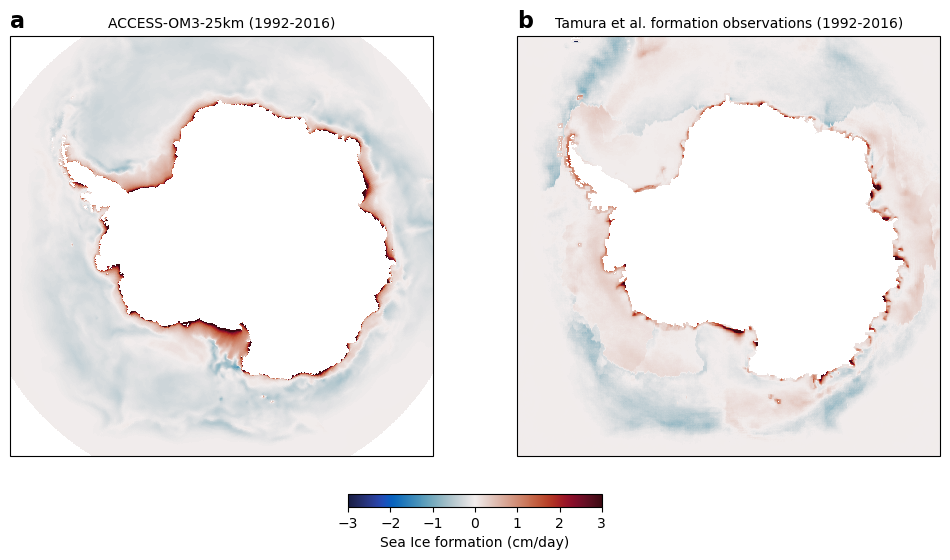

In [49]:
ft_size=16
fig, ax0 = plt.subplots(1,2, figsize=(12, 12), subplot_kw={"projection": ccrs.SouthPolarStereo()})

ax=ax0[0]
ax.pcolormesh(SIP_mean.TLON,SIP_mean.TLAT,SIP_mean,cmap=cm.cm.balance,transform=ccrs.PlateCarree(),
             vmin=-3,vmax=3)

om3_res='25km'
ax.set_extent([-180, 180, -90, -60], ccrs.PlateCarree())
ax.set_title(f'ACCESS-OM3-{om3_res} (1992-2016)',fontsize=ft_size-6)
ax.set_title('a', fontweight='bold', fontsize=ft_size, loc='left')


ax=ax0[1]
im = ax.pcolormesh(tamura_ds.lon,tamura_ds.lat,tamura_ds.ice_prod,cmap=cm.cm.balance,transform=ccrs.PlateCarree(),
             vmin=-3, vmax=3)

ax.set_extent([-180, 180, -90, -60], ccrs.PlateCarree())
ax.set_title(f'Tamura et al. formation observations (1992-2016)',fontsize=ft_size-6)
ax.set_title('b', fontweight='bold', fontsize=ft_size, loc='left')

cax = inset_axes(ax, width="60%", height="3%", loc="lower center",
                 bbox_to_anchor=(-.6, -0.12, 1, 1),
                 bbox_transform=ax.transAxes, borderpad=0)
cbar = fig.colorbar(im, cax=cax, orientation="horizontal")
cbar.set_label(r"Sea Ice formation (cm/day)")

### Now, test with dvidtt variable instead of -(meltt+meltb+meltl)

In [38]:
# Now try with dvidtt

SIP_dvidtt = datastore.search(variable="dvidtt").to_dask(
    xarray_combine_by_coords_kwargs = dict( # These kwargs can make things faster
        compat="override",
        data_vars="minimal",
        coords="minimal",
    ),
    xarray_open_kwargs = dict(
        chunks={"yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
        # chunks={"time": -1}, # Good for temporal operations, but not spatial
        decode_timedelta=True
    )
)

SIP_dvidtt = SIP_dvidtt.merge(grid)

# chop out a certain time range
SIP_dvidtt = SIP_dvidtt.sel(time=slice(date_start,date_end))

# chop out the data too far north
SIP_dvidtt = SIP_dvidtt.isel(nj=slice(0,300))

SIP_dvidtt["TLAT"] = SIP_dvidtt.TLAT.fillna(0)
SIP_dvidtt["TLON"] = SIP_dvidtt.TLON.fillna(0)

SIP_dvidtt_mean = SIP_dvidtt.dvidtt.mean(dim='time')


In [39]:
SIP_dvidtt_mean

<xarray.DataArray 'dvidtt' (nj: 300, ni: 1440)> Size: 2MB
dask.array<mean_agg-aggregate, shape=(300, 1440), dtype=float32, chunksize=(300, 480), chunktype=numpy.ndarray>
Coordinates:
    TLAT     (nj, ni) float32 2MB dask.array<chunksize=(300, 1440), meta=np.ndarray>
    TLON     (nj, ni) float32 2MB dask.array<chunksize=(300, 1440), meta=np.ndarray>
    ULON     (nj, ni) float32 2MB dask.array<chunksize=(300, 1440), meta=np.ndarray>
    ULAT     (nj, ni) float32 2MB dask.array<chunksize=(300, 1440), meta=np.ndarray>
    NLON     (nj, ni) float32 2MB dask.array<chunksize=(300, 1440), meta=np.ndarray>
    NLAT     (nj, ni) float32 2MB dask.array<chunksize=(300, 1440), meta=np.ndarray>
    ELON     (nj, ni) float32 2MB dask.array<chunksize=(300, 1440), meta=np.ndarray>
    ELAT     (nj, ni) float32 2MB dask.array<chunksize=(300, 1440), meta=np.ndarray>
Dimensions without coordinates: nj, ni
Attributes:
    units:          cm/day
    long_name:      volume tendency thermo
    cell_measures:  area: tarea
    cell_methods:   time: mean
    time_rep:       averaged

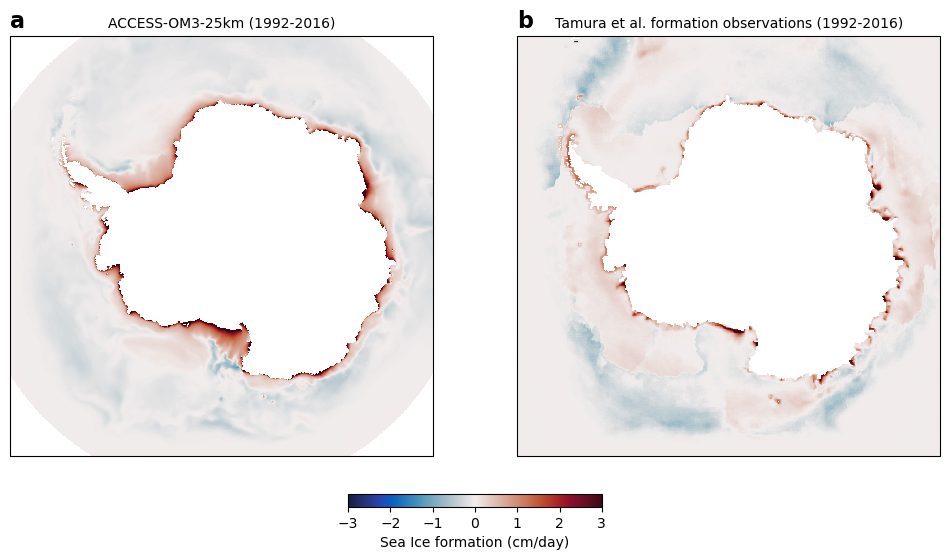

In [40]:
ft_size=16
fig, ax0 = plt.subplots(1,2, figsize=(12, 12), subplot_kw={"projection": ccrs.SouthPolarStereo()})

ax=ax0[0]
ax.pcolormesh(SIP_dvidtt.TLON,SIP_dvidtt.TLAT,SIP_dvidtt_mean,cmap=cm.cm.balance,transform=ccrs.PlateCarree(),
             vmin=-3,vmax=3)

om3_res='25km'
ax.set_extent([-180, 180, -90, -60], ccrs.PlateCarree())
ax.set_title(f'ACCESS-OM3-{om3_res} (1992-2016)',fontsize=ft_size-6)
ax.set_title('a', fontweight='bold', fontsize=ft_size, loc='left')


ax=ax0[1]
im = ax.pcolormesh(tamura_ds.lon,tamura_ds.lat,tamura_ds.ice_prod,cmap=cm.cm.balance,transform=ccrs.PlateCarree(),
             vmin=-3, vmax=3)

ax.set_extent([-180, 180, -90, -60], ccrs.PlateCarree())
ax.set_title(f'Tamura et al. formation observations (1992-2016)',fontsize=ft_size-6)
ax.set_title('b', fontweight='bold', fontsize=ft_size, loc='left')

cax = inset_axes(ax, width="60%", height="3%", loc="lower center",
                 bbox_to_anchor=(-.6, -0.12, 1, 1),
                 bbox_transform=ax.transAxes, borderpad=0)
cbar = fig.colorbar(im, cax=cax, orientation="horizontal")
cbar.set_label(r"Sea Ice formation (cm/day)")